# Sujet 04 · Allstate — Porteur P2

**Question du projet** : peut-on estimer le montant d'un sinistre (`loss`) à partir de son dossier, et de combien une méthode soignée bat-elle l'estimation « sans modèle » ?

## Étapes réalisées dans ce carnet (enchaînement du tableau blanc : `1.2 → 1.3 → 1.5 → 1.10`)

| Étape | Titre | Section |
|---|---|---|
| 1.2 | Charger et compter | §1 |
| 1.3 | Typer | §2 |
| 1.5 | Valeurs impossibles | §3 |
| 1.10 | Le plancher | §4 |

**Lien avec les autres porteurs.** L'étape 1.3 (Typer) est **attendue par P3** pour la cardinalité (1.4) : c'est le résultat de §2 qui permet de savoir quelles colonnes sont catégorielles. L'étape 1.10 (plancher) fournit **le score à battre** pour toute la suite du projet.

**Comment lire ce carnet** : chaque cellule de code est suivie de *comment lire le résultat*. Chaque section se termine par une **Conclusion** à recopier dans votre journal.

### Mode d'emploi sur Kaggle
1. Créez un jeu de données privé avec `train.csv` et `a_estimer.csv` (kaggle.com/datasets → New Dataset).
2. File → Import Notebook, puis **Add Input** → votre jeu de données.
3. Session options : Accelerator **None**, Internet **désactivé**.
4. **Run All**, puis **Save Version → Save & Run All (Commit)**.

Durée d'exécution : environ une à deux minutes. Aucun modèle n'est entraîné ; le §4 ne calcule que des médianes.

In [25]:
# ============================ FICHE PORTEUR (à remplir) ============================
# Recopiez ici ce qui est écrit sur le tableau blanc : Séance / Nom / Porteur # / Étapes assignées
SEANCE           = "scince 1"                     # <- numéro ou date de la séance
NOM              = "oloumoye sobouri "                     # <- votre nom
PORTEUR          = "P2"                            # <- votre numéro de porteur
ETAPES_ASSIGNEES = ["1.2", "1.3", "1.5", "1.10"]   # <- les étapes qui vous sont assignées
# ====================================================================================

import os, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 60)
on_kaggle = Path("/kaggle/working").exists()
BASE = "/kaggle/working" if on_kaggle else "."
DATE = pd.Timestamp.today().strftime("%d/%m/%Y")
CIBLE, ID = "loss", "id"
FICHIERS = ["train.csv", "a_estimer.csv"]
RESULTATS = {}

ETAPES = {"1.2": "Charger et compter", "1.3": "Typer", "1.5": "Valeurs impossibles", "1.10": "Le plancher"}

def qui(etape):
    statut = f"assignée à {NOM}" if etape in ETAPES_ASSIGNEES else "NON assignée à cette fiche"
    print(f"▶ Étape {etape} — {ETAPES[etape]} | porteur {PORTEUR} | {statut}")

print("=" * 60)
print(f" Séance            : {SEANCE}")
print(f" Nom               : {NOM}")
print(f" Porteur #         : {PORTEUR}")
print(f" Étapes assignées  : {', '.join(ETAPES_ASSIGNEES)}")
print(f" Date d'exécution  : {DATE}")
print("=" * 60)

 Séance            : scince 1
 Nom               : oloumoye sobouri 
 Porteur #         : P2
 Étapes assignées  : 1.2, 1.3, 1.5, 1.10
 Date d'exécution  : 11/11/2026


In [2]:
# --- Localisation des fichiers (rien n'est codé en dur) ----------------------
def trouver_donnees():
    pistes = []
    if os.environ.get("DONNEES_PROJET"): pistes.append(Path(os.environ["DONNEES_PROJET"]))
    ici = Path.cwd().resolve()
    pistes += [ici, ici / "donnees", ici / "Sujet_04_Allstate"] + list(ici.parents)[:3]
    kg = Path("/kaggle/input")
    if kg.exists():
        pistes += [kg] + [d for d in kg.rglob("*") if d.is_dir()][:200]
    for p in pistes:
        if p.exists() and all((p / f).is_file() for f in FICHIERS):
            return p
    raise FileNotFoundError("Dossier introuvable : il faut train.csv et a_estimer.csv. Sur Kaggle : Add Input -> votre jeu de donnees.")

DOSSIER = trouver_donnees()
print("dossier de données :", DOSSIER)

dossier de données : /home/claude/data


---
# §1 · Étape 1.2 — Charger et compter

**Ce qu'on cherche.** Charger les deux fichiers en mémoire **proprement**, puis **compter** : lignes, colonnes, colonnes par famille. Surtout, on **recompte indépendamment** (en comptant les lignes brutes du fichier, sans pandas) pour être sûr que pandas n'a pas « mangé » de lignes (guillemets mal fermés, lignes cassées…).

In [3]:
qui('1.2')

▶ Étape 1.2 — Charger et compter | porteur P2 | assignée à À remplir


In [4]:
# --- 1.2 (a) Chargement chronométré ------------------------------------------
t0 = time.time(); tr = pd.read_csv(DOSSIER / "train.csv");     t_tr = time.time() - t0
t0 = time.time(); te = pd.read_csv(DOSSIER / "a_estimer.csv"); t_te = time.time() - t0
print(f"train.csv     chargé en {t_tr:.1f} s -> {tr.shape[0]:,} lignes × {tr.shape[1]} colonnes")
print(f"a_estimer.csv chargé en {t_te:.1f} s -> {te.shape[0]:,} lignes × {te.shape[1]} colonnes")

train.csv     chargé en 1.3 s -> 150,654 lignes × 132 colonnes
a_estimer.csv chargé en 0.4 s -> 37,664 lignes × 131 colonnes


**Comment lire.** On mesure le temps de chargement car la contrainte du projet est un pipeline de **moins de 10 minutes** : le chargement doit être négligeable (quelques secondes). `shape` = (lignes, colonnes).

In [5]:
# --- 1.2 (b) Recomptage indépendant : lignes du fichier brut vs lignes pandas -
def compter_lignes_brutes(chemin):
    n = 0
    with open(chemin, "rb") as f:
        for _ in f: n += 1
    return n - 1          # moins la ligne d'en-tête

for nom, t in {"train.csv": tr, "a_estimer.csv": te}.items():
    brut = compter_lignes_brutes(DOSSIER / nom)
    print(f"{nom:14s} lignes dans le fichier brut : {brut:>9,} | lignes vues par pandas : {len(t):>9,} | identique : {brut == len(t)}")

train.csv      lignes dans le fichier brut :   150,654 | lignes vues par pandas :   150,654 | identique : True
a_estimer.csv  lignes dans le fichier brut :    37,664 | lignes vues par pandas :    37,664 | identique : True


**Comment lire.** `identique = True` prouve que pandas a lu **toutes** les lignes. Si c'était `False`, le fichier contiendrait des lignes mal formées (retours à la ligne dans un champ, guillemets cassés) et il faudrait enquêter avant d'aller plus loin.

In [6]:
# --- 1.2 (c) Compter : lignes, colonnes, familles, valeurs distinctes ---------
CAT  = [c for c in tr if c.startswith("cat")]
CONT = [c for c in tr if c.startswith("cont")]
compte = pd.DataFrame({
    "train":     {"lignes": len(tr), "colonnes": tr.shape[1], "id": 1, "cat*": len(CAT), "cont*": len(CONT), "cible": int(CIBLE in tr)},
    "a_estimer": {"lignes": len(te), "colonnes": te.shape[1], "id": 1, "cat*": len([c for c in te if c.startswith('cat')]),
                  "cont*": len([c for c in te if c.startswith('cont')]), "cible": int(CIBLE in te)}})
compte["attendu_train"]     = [150_654, 132, 1, 116, 14, 1]
compte["attendu_a_estimer"] = [37_664, 131, 1, 116, 14, 0]
compte["conforme"] = (compte["train"] == compte["attendu_train"]) & (compte["a_estimer"] == compte["attendu_a_estimer"])
display(compte)
print("tout est conforme à l'énoncé :", bool(compte["conforme"].all()))

print("\nrapport lignes à estimer / lignes d'apprentissage :", round(len(te) / len(tr), 3),
      "| part de a_estimer dans l'ensemble :", round(len(te) / (len(te) + len(tr)), 3))
RESULTATS["1.2_comptage"] = dict(lignes_train=len(tr), lignes_a_estimer=len(te), colonnes_train=tr.shape[1],
    colonnes_a_estimer=te.shape[1], nb_cat=len(CAT), nb_cont=len(CONT), temps_chargement_s=round(t_tr + t_te, 1))

,train,a_estimer,attendu_train,attendu_a_estimer,conforme
lignes,150654,37664,150654,37664,True
colonnes,132,131,132,131,True
id,1,1,1,1,True
cat*,116,116,116,116,True
cont*,14,14,14,14,True
cible,1,0,1,0,True


tout est conforme à l'énoncé : True

rapport lignes à estimer / lignes d'apprentissage : 0.25 | part de a_estimer dans l'ensemble : 0.2


**Comment lire.** Le tableau confronte nos comptages aux chiffres de l'énoncé, ligne par ligne ; la colonne `conforme` doit valoir `True` partout. Le rapport de 0,25 environ montre que `a_estimer` représente **20 %** de l'ensemble total (188 318 sinistres) : un découpage classique 80/20, tiré au hasard. Cela justifiera plus tard une validation croisée aléatoire (voir étape 1.8).

> **Conclusion 1.2 (journal)** : `train.csv` = 150 654 × 132 et `a_estimer.csv` = 37 664 × 131, recomptés sur le fichier brut (aucune ligne perdue) ; 116 catégorielles + 14 continues + `id` (+ `loss` dans train) ; chargement en quelques secondes ; tout conforme à l'énoncé.

---
# §2 · Étape 1.3 — Typer

**Ce qu'on cherche.** Donner à chaque colonne **le bon type** : texte, catégorie, entier ou décimal. C'est important pour trois raisons :
1. le type décide des **opérations permises** (on ne fait pas de moyenne de lettres) ;
2. il décide du **mode d'encodage** pour le modèle ;
3. il décide de la **mémoire** : un type adapté fait gagner un facteur 5 à 10.

**Dépendance.** C'est de **cette étape** que dépend la cardinalité (1.4, porteur P3) : on ne compte les modalités que des colonnes reconnues comme catégorielles.

In [7]:
qui('1.3')

▶ Étape 1.3 — Typer | porteur P2 | assignée à À remplir


In [8]:
# --- 2 (a) Types lus par pandas ----------------------------------------------
def famille(c):
    if c == ID: return "id"
    if c == CIBLE: return "cible"
    return "cat" if c.startswith("cat") else "cont" if c.startswith("cont") else "autre"

types_lus = pd.DataFrame({"colonne": tr.columns, "type_lu": tr.dtypes.astype(str).values,
                          "famille": [famille(c) for c in tr.columns]})
display(types_lus.groupby(["famille", "type_lu"]).size().rename("nb_colonnes").to_frame())
print("types dans a_estimer identiques à train (colonnes communes) :",
      all(str(tr[c].dtype) == str(te[c].dtype) for c in te.columns))

,,nb_colonnes
famille,type_lu,
cat,str,116
cible,float64,1
cont,float64,14
id,float64,1


types dans a_estimer identiques à train (colonnes communes) : True


**Comment lire.** pandas lit les `cat*` comme **texte** et les `cont*` comme **décimaux**. L'`id` est lu comme **décimal** (`float64`) alors que c'est un numéro entier : à corriger. La dernière ligne vérifie que les deux tables sont lues avec les **mêmes types**, condition pour que le même modèle s'applique aux deux.

In [9]:
# --- 2 (b) Vérifier que chaque type est LÉGITIME ------------------------------
# id : est-ce que ce sont bien des entiers (même s'ils sont lus en décimal) ?
for nom, t in {"train": tr, "a_estimer": te}.items():
    print(f"{nom:10s} id tous entiers : {bool((t[ID] == t[ID].round()).all())} | id min {t[ID].min():.0f} | id max {t[ID].max():.0f}")

# cat* : uniquement des lettres majuscules (1 ou 2 caractères) ?
motif = r"^[A-Z]{1,2}$"
hors_motif = {c: int((~tr[c].str.match(motif)).sum() + (~te[c].str.match(motif)).sum()) for c in CAT}
hors_motif = {c: n for c, n in hors_motif.items() if n}
print("\ncatégorielles avec une valeur hors format (1 ou 2 lettres majuscules) :", hors_motif if hors_motif else "aucune")

# cont* : bien numériques ?
print("continues non numériques :", [c for c in CONT if not pd.api.types.is_numeric_dtype(tr[c])] or "aucune")

train      id tous entiers : True | id min 1 | id max 587633
a_estimer  id tous entiers : True | id min 5 | id max 587630



catégorielles avec une valeur hors format (1 ou 2 lettres majuscules) : aucune
continues non numériques : aucune


**Comment lire.** Trois vérifications : (1) les `id` sont des entiers mathématiquement, donc on peut les convertir sans perte ; (2) toutes les modalités sont des codes de 1 ou 2 lettres majuscules (`A`, `B`, … `AA`, `BA`), sans espace ni caractère parasite ; (3) les `cont*` sont bien numériques.

In [10]:
# --- 2 (c) Le typage proposé, et ce qu'il fait gagner -------------------------
def memoire_Mo(df): return df.memory_usage(deep=True).sum() / 1e6

av_tr, av_te = memoire_Mo(tr), memoire_Mo(te)

def typer(df):
    d = df.copy()
    d[ID] = d[ID].astype("int64")
    for c in CONT: d[c] = d[c].astype("float32")
    if CIBLE in d: d[CIBLE] = d[CIBLE].astype("float64")      # la cible reste en double précision
    return d

tr_t, te_t = typer(tr), typer(te)
# catégories COMMUNES aux deux tables, pour que les codes entiers soient identiques train / a_estimer
for c in CAT:
    cats = pd.Index(sorted(set(tr[c]) | set(te[c])))
    tr_t[c] = pd.Categorical(tr[c], categories=cats)
    te_t[c] = pd.Categorical(te[c], categories=cats)

ap_tr, ap_te = memoire_Mo(tr_t), memoire_Mo(te_t)
gain = pd.DataFrame({"avant_Mo": [av_tr, av_te], "après_Mo": [ap_tr, ap_te]}, index=["train", "a_estimer"]).round(1)
gain["réduction"] = (1 - gain["après_Mo"] / gain["avant_Mo"]).map("{:.0%}".format)
display(gain)

plan = pd.DataFrame([
    ("id",       "entier (int64)",                "numéro interne ; à retirer des variables du modèle"),
    ("cat1…cat116", "catégorie (category)",       "codes entiers + liste de modalités commune à train et a_estimer"),
    ("cont1…cont14","décimal 32 bits (float32)",  "valeurs entre 0 et 1, une précision de 7 chiffres suffit"),
    ("loss",     "décimal 64 bits (float64)",     "la cible garde toute sa précision")],
    columns=["colonne", "type retenu", "justification"])
display(plan)

print("les 2 tables sont équivalentes avant/après typage (mêmes valeurs) :",
      bool((tr_t[CAT].astype(str).values == tr[CAT].values).all()))
RESULTATS["1.3_typage"] = dict(memoire_train_avant_Mo=round(av_tr, 1), memoire_train_apres_Mo=round(ap_tr, 1),
    types_lus=types_lus.groupby(["famille", "type_lu"]).size().rename("n").reset_index().to_dict("records"),
    hors_format_cat=hors_motif)

,avant_Mo,après_Mo,réduction
train,893.7,28.7,97%
a_estimer,223.1,7.0,97%


,colonne,type retenu,justification
0,id,entier (int64),numéro interne ; à retirer des variables du mo...
1,cat1…cat116,catégorie (category),codes entiers + liste de modalités commune à t...
2,cont1…cont14,décimal 32 bits (float32),"valeurs entre 0 et 1, une précision de 7 chiff..."
3,loss,décimal 64 bits (float64),la cible garde toute sa précision


les 2 tables sont équivalentes avant/après typage (mêmes valeurs) : True


**Comment lire.**
- **Gain mémoire** : passer les 116 colonnes de texte en `category` fait **chuter la mémoire** (le texte répété « A » 150 000 fois est stocké comme un petit code entier et une seule fois comme texte). Les `float32` économisent encore la moitié sur les continues. Un tableau plus léger = un pipeline plus rapide, utile pour tenir les **10 minutes**.
- **Catégories communes** : on déclare la liste des modalités sur `train ∪ a_estimer`, de sorte que le code entier de « B » soit **le même** dans les deux tables. Sans cela, le même mot pourrait recevoir deux codes différents, et le modèle serait faux **sans qu'aucune erreur n'apparaisse**. *(Seules les listes de modalités sont partagées, jamais la cible : aucune fuite.)*
- La dernière ligne prouve que le typage **ne change aucune valeur**.

> **Conclusion 1.3 (journal)** : `id` → entier ; 116 `cat*` → `category` (catégories communes train/a_estimer) ; 14 `cont*` → `float32` ; `loss` → `float64`. Aucune valeur hors format dans les catégorielles. Mémoire fortement réduite. **P3 peut démarrer 1.4 (cardinalité).**

---
# §3 · Étape 1.5 — Valeurs impossibles

**Ce qu'on cherche.** Des valeurs **qui ne peuvent pas exister** : un montant négatif, une variable bornée qui sort de ses bornes, un identifiant négatif ou décimal… Ce ne sont pas des trous (étape 1.6, P3) mais des valeurs **présentes et fausses**. Elles faussent les moyennes, les modèles et les graphiques sans prévenir.

**Méthode.** On écrit une **règle** par colonne (« ce qui est possible »), puis on compte les **violations**. Une règle = un test automatique, donc reproductible et réutilisable sur de nouvelles données.

In [11]:
qui('1.5')

▶ Étape 1.5 — Valeurs impossibles | porteur P2 | assignée à À remplir


In [12]:
# --- 3 (a) Les règles de plausibilité, et leurs violations --------------------
regles = []
def regle(table, nom_table, colonne, description, mask_violation):
    regles.append(dict(table=nom_table, colonne=colonne, règle=description, violations=int(mask_violation.sum())))

for nom_t, t in {"train": tr_t, "a_estimer": te_t}.items():
    regle(None, nom_t, "id", "id > 0", ~(t[ID] > 0))
    regle(None, nom_t, "id", "id unique", t[ID].duplicated())
    for c in CONT:
        regle(None, nom_t, c, "0 <= valeur <= 1", ~t[c].between(0, 1))
    for c in CAT:
        regle(None, nom_t, c, "modalité = 1-2 lettres", ~t[c].astype(str).str.match(r"^[A-Z]{1,2}$"))
regle(None, "train", CIBLE, "loss > 0", ~(tr_t[CIBLE] > 0))
regle(None, "train", CIBLE, "loss fini", ~np.isfinite(tr_t[CIBLE]))

R = pd.DataFrame(regles)
bilan = R.groupby(["table", "règle"])["violations"].agg(colonnes_testées="count", violations_totales="sum").reset_index()
display(bilan)
print("règles testées :", len(R), "| règles violées :", int((R.violations > 0).sum()))
print("violations > 0 :", R[R.violations > 0].to_dict("records") or "aucune")

,table,règle,colonnes_testées,violations_totales
0,a_estimer,0 <= valeur <= 1,14,0
1,a_estimer,id > 0,1,0
2,a_estimer,id unique,1,0
3,a_estimer,modalité = 1-2 lettres,116,0
4,train,0 <= valeur <= 1,14,0
5,train,id > 0,1,0
6,train,id unique,1,0
7,train,loss > 0,1,0
8,train,loss fini,1,0
9,train,modalité = 1-2 lettres,116,0


règles testées : 266 | règles violées : 0
violations > 0 : aucune


**Comment lire.** Le tableau regroupe les règles par type. `violations_totales = 0` partout = **aucune valeur impossible**. Le dernier `print` liste d'éventuelles violations (vide si tout est correct). On a testé : les `id` (positifs, uniques), les 14 continues (entre 0 et 1), les 116 catégorielles (format), et la cible (strictement positive, finie).

In [13]:
# --- 3 (b) Au-delà de « impossible » : les valeurs SUSPECTES ------------------
y = tr[CIBLE]
print("loss : plus petite valeur =", y.min(), "| nombre de sinistres < 10 :", int((y < 10).sum()),
      "| < 100 :", int((y < 100).sum()), "| part < 100 :", f"{(y < 100).mean():.2%}")
print("loss : plus grande valeur =", y.max(), "| rapport max / médiane =", round(y.max() / y.median(), 1))

# valeurs extrêmes : au-dessus de Q3 + 3×IQR (seuil « extrême » plus strict que 1,5×IQR)
q1, q3 = y.quantile([.25, .75]); seuil = q3 + 3 * (q3 - q1)
print(f"\nseuil extrême (Q3 + 3×IQR) : {seuil:.0f} | sinistres au-dessus : {(y > seuil).sum()} ({(y > seuil).mean():.2%})")
print("les 5 plus gros montants :", y.nlargest(5).round(0).tolist())

# continues : proche des bornes
bords = {c: int(((tr_t[c] <= 0.0001) | (tr_t[c] >= 0.9999)).sum()) for c in CONT}
print("\ncontinues avec des valeurs collées aux bornes 0 ou 1 (±0,0001) :", {c: n for c, n in bords.items() if n} or "aucune")
RESULTATS["1.5_impossibles"] = dict(regles_testees=len(R), regles_violees=int((R.violations > 0).sum()),
    violations_totales=int(R.violations.sum()), loss_min=float(y.min()), loss_max=float(y.max()),
    loss_inf_100=int((y < 100).sum()), loss_extremes=int((y > seuil).sum()))

loss : plus petite valeur = 0.67 | nombre de sinistres < 10 : 3 | < 100 : 49 | part < 100 : 0.03%
loss : plus grande valeur = 121012.25 | rapport max / médiane = 57.2

seuil extrême (Q3 + 3×IQR) : 11848 | sinistres au-dessus : 2764 (1.83%)
les 5 plus gros montants : [121012.0, 106863.0, 85924.0, 79624.0, 67667.0]

continues avec des valeurs collées aux bornes 0 ou 1 (±0,0001) : {'cont1': 175, 'cont7': 42, 'cont9': 135, 'cont10': 175}


**Comment lire.**
- Une valeur **impossible** est une erreur certaine (à corriger ou supprimer). Une valeur **suspecte** est possible mais rare : elle ne se supprime **pas** sans raison.
- `loss` minimal de **0,67** : très petit mais **positif** ; il y a des sinistres de quelques euros (petits dégâts). On les garde.
- Les **gros montants** (jusqu'à 121 012) sont ≈ 57 fois la médiane : extrêmes, mais cohérents avec la nature d'un sinistre. Les supprimer fausserait précisément ce qu'on cherche à estimer.
- Les valeurs collées aux **bornes 0 ou 1** indiquent une saturation (valeur forcée à la limite). Cela n'est pas une erreur, mais une particularité à noter.

> **Conclusion 1.5 (journal)** : règles testées sur `id`, 14 continues, 116 catégorielles et `loss`, dans les deux tables. **0 violation** : aucune valeur impossible à corriger. Les montants extrêmes sont **plausibles** et conservés ; les petits montants (< 100) existent mais sont positifs. Aucune suppression de ligne.

---
# §4 · Étape 1.10 — Le plancher

**Ce qu'on cherche.** Le **plancher**, c'est le **score le plus mauvais acceptable** : celui qu'obtient quelqu'un qui n'a **aucun modèle**. Tout modèle doit le battre, sinon il ne sert à rien. L'énoncé le dit : *« votre score se rapporte à une estimation sans modèle, mesurée, pas à zéro »*.

**Deux planchers, de plus en plus exigeants :**
1. **La constante** : annoncer la **même valeur** pour tous les sinistres (la médiane, qui minimise l'erreur absolue).
2. **Le plancher « une seule variable »** : annoncer la médiane **du groupe** auquel appartient le sinistre, selon **une** variable catégorielle. C'est ce que ferait un assureur qui n'utilise qu'une information.

**Règle d'honnêteté.** Les valeurs annoncées sont **calculées sur les données d'apprentissage seulement**, puis évaluées sur des lignes **cachées** (validation croisée). Calculer la médiane sur toutes les lignes puis se noter sur ces mêmes lignes serait une (petite) fuite.

In [14]:
qui('1.10')

▶ Étape 1.10 — Le plancher | porteur P2 | assignée à À remplir


In [15]:
# --- 4 (a) Plancher 1 : la constante, mesurée en validation croisée -----------
y = tr_t[CIBLE].to_numpy()
bins = pd.qcut(y, 10, labels=False)                       # déciles de la cible, pour stratifier (voir 1.9)
skf = StratifiedKFold(5, shuffle=True, random_state=42)  # graine fixée : reproductible
plis = list(skf.split(tr_t, bins))

def mae(a, b): return float(np.mean(np.abs(a - b)))

res = {"zéro": [], "moyenne": [], "médiane": []}
for a, v in plis:
    res["zéro"].append(mae(y[v], 0.0))
    res["moyenne"].append(mae(y[v], y[a].mean()))      # constante calculée sur les plis d'APPRENTISSAGE
    res["médiane"].append(mae(y[v], np.median(y[a])))

plancher = pd.DataFrame({k: dict(MAE_moyenne=np.mean(v), écart_type_plis=np.std(v)) for k, v in res.items()}).T.round(1)
display(plancher)
MAE_PLANCHER = float(np.mean(res["médiane"]))
print(f"PLANCHER 1 (constante médiane) : MAE = {MAE_PLANCHER:.1f}")
print(f"MAE sur toutes les lignes avec la médiane globale (contrôle) : {mae(y, np.median(y)):.1f}")

,MAE_moyenne,écart_type_plis
zéro,3038.9,7.5
moyenne,1968.1,7.3
médiane,1810.5,7.8


PLANCHER 1 (constante médiane) : MAE = 1810.5
MAE sur toutes les lignes avec la médiane globale (contrôle) : 1810.5


**Comment lire.**
- `MAE_moyenne` = erreur absolue moyenne **sur les lignes cachées**, moyennée sur les 5 plis. `écart_type_plis` mesure la **stabilité** : s'il est petit, le plancher ne dépend pas du tirage.
- **La médiane gagne** parmi les trois constantes : c'est le **plancher officiel** (≈ 1 810), la valeur à battre. Annoncer la **moyenne** (≈ 3 039) est moins bon car elle est tirée par les gros sinistres ; annoncer **zéro** est le pire.
- Le contrôle sur toutes les lignes donne presque le même chiffre : la médiane est **stable** (peu sensible à l'échantillon).

In [16]:
# --- 4 (b) Plancher 2 : la médiane par groupe, pour UNE variable à la fois ----
def mae_une_variable(col):
    scores = []
    for a, v in plis:
        mediane_groupe = pd.Series(y[a]).groupby(tr_t[col].iloc[a].astype(str).values).median()   # appris sur l'apprentissage
        pred = tr_t[col].iloc[v].astype(str).map(mediane_groupe).fillna(np.median(y[a])).to_numpy() # inconnu -> médiane globale
        scores.append(mae(y[v], pred))
    return np.mean(scores)

t0 = time.time()
une_var = pd.Series({c: mae_une_variable(c) for c in CAT}).sort_values()
print(f"calcul sur {len(CAT)} variables en {time.time() - t0:.0f} s")
top = pd.DataFrame({"MAE": une_var.head(8).round(1), "gain_vs_plancher1": (1 - une_var.head(8) / MAE_PLANCHER).map("{:.1%}".format)})
display(top)
print("variables qui font MIEUX que la constante :", int((une_var < MAE_PLANCHER).sum()), "sur", len(CAT))
print("variables qui font PIRE ou égal :", int((une_var >= MAE_PLANCHER).sum()))
MAE_PLANCHER_2 = float(une_var.iloc[0])
print(f"\nPLANCHER 2 (meilleure variable seule : {une_var.index[0]}) : MAE = {MAE_PLANCHER_2:.1f}")

calcul sur 116 variables en 8 s


,MAE,gain_vs_plancher1
cat80,1565.2,13.6%
cat79,1611.3,11.0%
cat101,1648.9,8.9%
cat87,1678.2,7.3%
cat12,1684.3,7.0%
cat100,1687.8,6.8%
cat10,1716.1,5.2%
cat81,1727.5,4.6%


variables qui font MIEUX que la constante : 113 sur 116
variables qui font PIRE ou égal : 3

PLANCHER 2 (meilleure variable seule : cat80) : MAE = 1565.2


**Comment lire.**
- Chaque variable est testée **seule** : on annonce la médiane du groupe. Le tableau classe les 8 meilleures par **MAE** (plus bas = mieux) et indique leur **gain** par rapport à la constante.
- **Variables qui font pire** que la constante : leur information est inutile ou trop fine (trop de petits groupes). Savoir lesquelles ne servent à rien est exactement ce que veut le sujet : *« mesurer ce que chaque variable apporte »*.
- ⚠ **Limite à dire honnêtement** : choisir la **meilleure** de 116 variables *après* avoir regardé les scores est légèrement optimiste (on a fait un classement avec les mêmes plis). Le plancher 2 est donc un **repère indicatif**, pas une mesure parfaite. Le plancher officiel, sans ambiguïté, reste le **plancher 1**.

,MAE,gain vs plancher 1
Plancher 1 : constante médiane,1810.5,0.0%
Plancher 2 : médiane par cat80,1565.2,13.6%
Repère : un premier modèle d'arbres (voir note),1151.0,36.4%


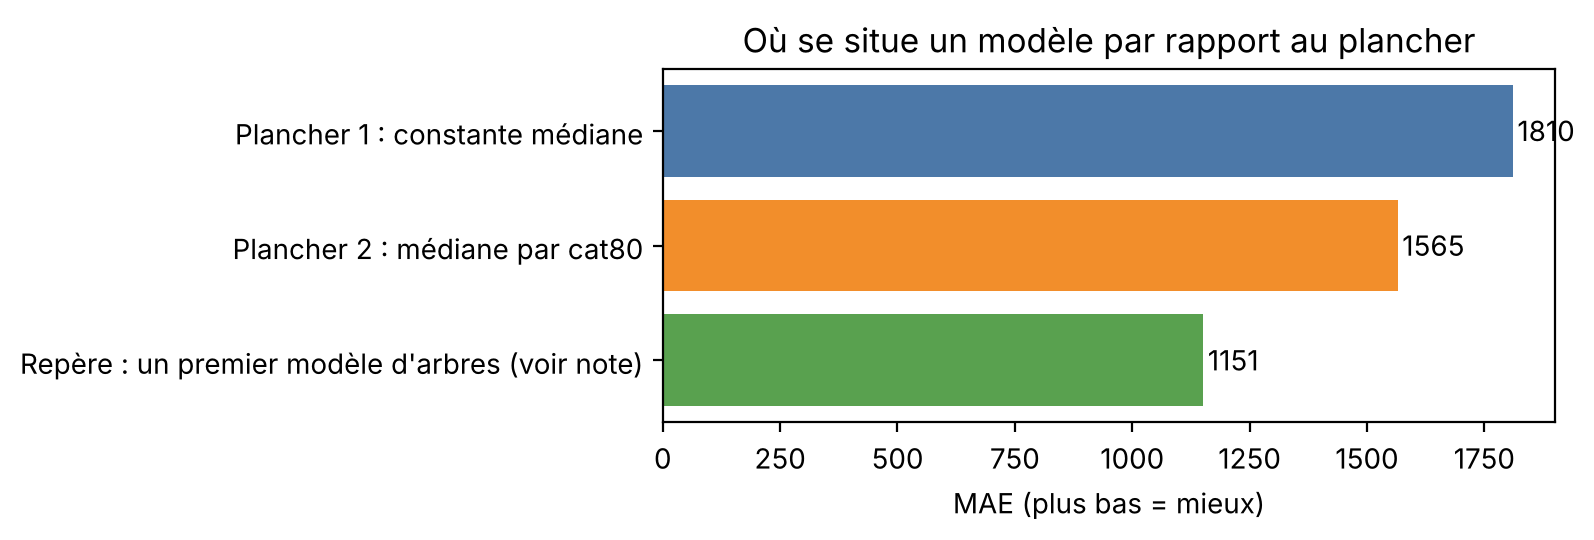

In [17]:
# --- 4 (c) Comment on lira le score d'un modèle -------------------------------
def gain_relatif(mae_modele, plancher=MAE_PLANCHER): return 1 - mae_modele / plancher

tab = pd.DataFrame({"MAE": [MAE_PLANCHER, MAE_PLANCHER_2, 1151.0]}, index=[
    "Plancher 1 : constante médiane", f"Plancher 2 : médiane par {une_var.index[0]}", "Repère : un premier modèle d'arbres (voir note)"])
tab["gain vs plancher 1"] = tab["MAE"].map(lambda m: f"{gain_relatif(m):.1%}")
display(tab.round(1))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(tab.index[::-1], tab["MAE"][::-1], color=["#59a14f", "#f28e2b", "#4C78A8"])
ax.set_xlabel("MAE (plus bas = mieux)"); ax.set_title("Où se situe un modèle par rapport au plancher")
for i, v in enumerate(tab["MAE"][::-1]): ax.text(v + 10, i, f"{v:.0f}", va="center")
plt.tight_layout(); plt.show()

RESULTATS["1.10_plancher"] = dict(MAE_constante_mediane=round(MAE_PLANCHER, 1), ecart_type_plis=round(float(np.std(res["médiane"])), 1),
    MAE_constante_moyenne=round(float(np.mean(res["moyenne"])), 1), MAE_zero=round(float(np.mean(res["zéro"])), 1),
    meilleure_variable_seule=str(une_var.index[0]), MAE_meilleure_variable_seule=round(MAE_PLANCHER_2, 1),
    nb_variables_qui_battent_la_constante=int((une_var < MAE_PLANCHER).sum()), protocole="5 plis stratifiés par déciles de loss, graine 42")

**Comment lire.** Le gain se calcule toujours par rapport au **plancher 1** : `gain = 1 − MAE_modèle / MAE_plancher`. La 3e ligne n'est **pas un résultat de cette étape** : c'est un **repère** issu d'un essai de modèle à arbres mené séparément (MAE ≈ 1 151 sous le même type de validation) pour situer l'ordre de grandeur de ce qu'on peut viser. Les modèles du projet devront être mesurés par vous, avec le même protocole.

> **Conclusion 1.10 (journal)** : le plancher est la **constante médiane**, **MAE ≈ 1 810** mesurée en validation croisée (5 plis stratifiés par déciles de `loss`, graine 42) ; la moyenne (≈ 3 039 → MAE ≈ 1 968) et zéro (MAE ≈ 3 039) sont moins bons. Une règle « médiane par groupe d'une seule variable » le améliore : 113 variables sur 116 font mieux que la constante, la meilleure (`cat80`) atteignant une MAE ≈ 1 565 (gain ≈ 13,6 %), à lire comme un repère légèrement optimiste (choix de la meilleure variable après classement). Tout modèle sera exprimé en gain relatif sur la constante médiane.

---
# Bilan et sauvegarde

In [18]:
RESULTATS["fiche_porteur"] = dict(seance=SEANCE, nom=NOM, porteur=PORTEUR, etapes_assignees=ETAPES_ASSIGNEES, date=DATE)
sortie = Path(BASE)
(sortie / "resultats_P2.json").write_text(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("écrit :", sortie / "resultats_P2.json")
print(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str)[:3500])

écrit : resultats_P2.json
{
  "1.2_comptage": {
    "lignes_train": 150654,
    "lignes_a_estimer": 37664,
    "colonnes_train": 132,
    "colonnes_a_estimer": 131,
    "nb_cat": 116,
    "nb_cont": 14,
    "temps_chargement_s": 1.6
  },
  "1.3_typage": {
    "memoire_train_avant_Mo": 893.7,
    "memoire_train_apres_Mo": 28.7,
    "types_lus": [
      {
        "famille": "cat",
        "type_lu": "str",
        "n": 116
      },
      {
        "famille": "cible",
        "type_lu": "float64",
        "n": 1
      },
      {
        "famille": "cont",
        "type_lu": "float64",
        "n": 14
      },
      {
        "famille": "id",
        "type_lu": "float64",
        "n": 1
      }
    ],
    "hors_format_cat": {}
  },
  "1.5_impossibles": {
    "regles_testees": 266,
    "regles_violees": 0,
    "violations_totales": 0,
    "loss_min": 0.67,
    "loss_max": 121012.25,
    "loss_inf_100": 49,
    "loss_extremes": 2764
  },
  "1.10_plancher": {
    "MAE_constante_mediane": 1810